# Fixed-income allocation under withdrawals
## Reproduction, measurement corrections and external validation

**November 19, 2026 · Columbia University / Wedmont project**

This report starts from Tanish's November 10 employer demonstration and the source at
`4b0c23ec63f760feb8bcfbaecddd5746921f21d4`. It evaluates three questions.

1. At each initial real withdrawal rate, what bond allocation meets a specified spending-success target?
2. How do the answers change with observed Treasury ETF returns and historical estimation windows?
3. Does an allocation fitted to both age and planned cash flows outperform an age-only allocation in later historical data?

The comparisons use the existing monthly holdings ledger, with explicit contributions, funded withdrawals,
rebalancing and trading costs. Results and dataset definitions are linked to their run records.
[Original source](https://github.com/tanishpatel0106/FI-Acc-Dec-Wedmont/tree/4b0c23ec63f760feb8bcfbaecddd5746921f21d4)


In [1]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'backend' / 'lifecycle').exists())
OUT = ROOT / 'research' / 'followup_2026_11_19'
FIGURES = OUT / 'figures'
FIGURES.mkdir(exist_ok=True)
def read(name):
    return json.loads((OUT / name).read_text(encoding='utf-8'))
def results(record):
    return read(record['run_id'] + '.json')
main = read('main_runs.json')
model = read('main_frontier_runs.json')
observed = read('observed_frontier_runs.json')
plt.rcParams.update({'figure.dpi': 130, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
def export(name):
    plt.savefig(FIGURES / (name + '.png'), dpi=180, bbox_inches='tight')
    plt.show()


## Data selection and provenance

The long-history panel contains US equity returns, T-bills and Treasury returns reconstructed from yields.
Its purpose is to evaluate long retirement horizons. The separate validation panel adds observed IEF ETF
returns and GLD gold-fund returns. IEF targets Treasury maturities of seven to ten years, which makes it a
practical comparison for the modelled ten-year Treasury sleeve. The matched comparison uses the same equity,
inflation, cash, start month and end month across both bond sources.

ETF returns are computed as the percentage change in month-end daily adjusted closes. The raw responses,
retrieval URLs and SHA-256 hashes are retained. The final month is September 2026 to match the original public
snapshot. The first price month supplies the starting price and contributes no return observation.

Thirty-year ETF simulations resample a shorter observed history. Completed historical holdouts use only
cohorts that fit within the available data. The classic Permanent Portfolio experiment combines observed GLD
with the original Treasury sleeve, whose return reconstruction remains explicit.
[IEF issuer documentation](https://www.ishares.com/us/products/239456/ishares-710-year-treasury-bond-etf) ·
[Federal Reserve yield-curve research](https://www.federalreserve.gov/econres/feds/the-us-treasury-yield-curve-1961-to-the-present.htm) ·
[Original data pipeline](https://github.com/tanishpatel0106/FI-Acc-Dec-Wedmont/tree/main/backend/lifecycle/data)


In [2]:
sources = read('observed_data_sources.json')
display(pd.DataFrame(sources)[['ticker', 'series_id', 'first_month', 'last_month', 'months', 'sha256']])
records = [{'study': k, **v} for k,v in main.items()]
records += [{'study': k, **v} for k,v in model.items()]
records += [{'study': k, **v} for k,v in observed.items()]
manifest = pd.DataFrame(records)
display(manifest[['study','run_id','catalog_hash','engine_version']])


,ticker,series_id,first_month,last_month,months,sha256
0,IEF,ust_7_10_etf,2002-09-30,2026-09-30,289,aaff89913b2f0fb4c70aa044c2160904a686a1ee6388f9...
1,GLD,gold,2005-01-31,2026-09-30,261,32817e5b7ce1d36b229a5cb004c49eefa1d7c3ae05a045...


,study,run_id,catalog_hash,engine_version
0,frontier,15396257c3d3bfcb163e,3bbcce4a7278f089,0.2.3+d711933ba962
1,signed_flow,3c15e68b970135cb144d,3bbcce4a7278f089,0.2.3+d711933ba962
2,rebalance,b42f4a607fb70c037045,3bbcce4a7278f089,0.2.3+d711933ba962
3,scenario_lab,29194f5a9e962706c75f,3bbcce4a7278f089,0.2.3+d711933ba962
4,optimize,ea3c0f79c972a42d7904,3bbcce4a7278f089,0.2.3+d711933ba962
5,compare_v2,0f2900dc65ded619c306,3bbcce4a7278f089,0.2.3+d711933ba962
6,asof,32ed9ceea7d75f71c9c3,3bbcce4a7278f089,0.2.3+d711933ba962
7,evidence,5e4fd33677a8a24b59e1,3bbcce4a7278f089,0.2.3+d711933ba962
8,historical_replay,31c4d46f75f7e5ceb2fd,3bbcce4a7278f089,0.2.3+d711933ba962
9,lifecycle_sim,f6600f0e20c4594918a3,3bbcce4a7278f089,0.2.3+d711933ba962


## Corrections and evaluation design

| Calculation | Original implementation | Corrected implementation |
|---|---|---|
| Frontier objectives | 30-year success compared with 40-year consumption utility under default settings | Both objectives use 30 years |
| Young investor horizons | End age raised to at least 70, extending a declared 10- or 20-year experiment | End age equals starting age plus the declared horizon |
| Cash-flow comparison intervals | Variation across age/flow cells treated as sampling uncertainty | Paired simulation paths resampled jointly across cells, with fitted policies held fixed |
| Tail spending loss | Quantile ties at zero could make the reported tail mean equal the overall mean | Worst 5% of probability mass, with fractional weight at the boundary |
| Run identity | Dataset and specification determine the cache key | Scientific engine version also enters the key |

The frontier extension uses 5,000 bootstrap paths, 300 joint path resamples, a five-percentage-point bond grid
and withdrawal rates from 3% to 6% in 0.25-percentage-point steps. Risk-aversion values 2, 4, 6 and 8 are
reported. A Student-t scenario comparison and a five-basis-point execution-cost comparison are included.

The objective-selection holdout fits allocations on 5,000 paths and evaluates them on 10,000 separate paths.
The chronological cash-flow test fits on 4,000 paths drawn solely from pre-split history and freezes the
allocations before scoring later observed returns. Historical cohort results are descriptive because their
windows overlap.


In [3]:
frontier_rows = []
for name, record in {**model, **observed}.items():
    if record['kind'] != 'frontier':
        continue
    r = results(record)
    threshold = r['thresholds']['30|0.90']
    uncertainty = r['threshold_bootstrap']['30|0.90']
    for rate in [0.04, 0.045, 0.05, 0.055]:
        i = int(np.argmin(np.abs(np.array(r['r']) - rate)))
        row, boot = threshold[i], uncertainty[i]
        p = np.array(r['p_success']['30'])[:,i]
        frontier_rows.append({'sample':name, 'withdrawal_rate':rate,
                             'minimum_bond_share':row['b_min'], 'status':row['status'],
                             'best_success':p.max(), 'all_equity_success':p[0],
                             'bootstrap_no_feasible_share':boot['share_unidentified'],
                             'bond_share_q05':boot['q05'], 'bond_share_q95':boot['q95']})
threshold_table = pd.DataFrame(frontier_rows)
threshold_table.to_csv(OUT / 'frontier_summary.csv', index=False)
display(threshold_table.round(4))
early_model=threshold_table[(threshold_table['sample']=='matched_model_2002_2013') & np.isclose(threshold_table['withdrawal_rate'],.05)].iloc[0]
early_ief=threshold_table[(threshold_table['sample']=='ief_2002_2013') & np.isclose(threshold_table['withdrawal_rate'],.05)].iloc[0]
display(Markdown(f"At a 5% withdrawal rate, calibration on September 2002 through December 2013 "
    f"produces a best success rate of **{early_model['best_success']:.2%}** with reconstructed Treasury returns "
    f"and **{early_ief['best_success']:.2%}** with observed IEF returns. "
    f"The IEF version requires at least **{early_ief['minimum_bond_share']:.0%}** bonds on the tested grid to reach 90% success. "
    "Both tests use the same equity and inflation observations. This identifies material sensitivity to the bond return measurement."))


,sample,withdrawal_rate,minimum_bond_share,status,best_success,all_equity_success,bootstrap_no_feasible_share,bond_share_q05,bond_share_q95
0,1953_full,0.040,0.00,no_bonds_needed,0.9568,0.9458,0.0000,0.00,0.00
1,1953_full,0.045,0.00,no_bonds_needed,0.9214,0.9144,0.0000,0.00,0.00
2,1953_full,0.050,NaN,no_feasible_allocation,0.8700,0.8694,1.0000,NaN,NaN
3,1953_full,0.055,NaN,no_feasible_allocation,0.8182,0.8182,1.0000,NaN,NaN
4,1990_onward,0.040,0.00,no_bonds_needed,0.9838,0.9572,0.0000,0.00,0.00
5,1990_onward,0.045,0.00,no_bonds_needed,0.9530,0.9296,0.0000,0.00,0.00
6,1990_onward,0.050,0.05,identified,0.9088,0.8970,0.0067,0.00,0.15
7,1990_onward,0.055,NaN,no_feasible_allocation,0.8612,0.8564,1.0000,NaN,NaN
8,1990_onward_cost5bps,0.040,0.00,no_bonds_needed,0.9838,0.9572,0.0000,0.00,0.00
9,1990_onward_cost5bps,0.045,0.00,no_bonds_needed,0.9528,0.9292,0.0000,0.00,0.00


At a 5% withdrawal rate, calibration on September 2002 through December 2013 produces a best success rate of **88.96%** with reconstructed Treasury returns and **92.70%** with observed IEF returns. The IEF version requires at least **35%** bonds on the tested grid to reach 90% success. Both tests use the same equity and inflation observations. This identifies material sensitivity to the bond return measurement.

## Withdrawal success and minimum bond allocation

The heatmaps compare the two bond sources over identical dates. The minimum-bond table reports a missing
value when every tested allocation falls below 90% success. The reported bootstrap quantiles describe
replicates with a feasible allocation, alongside the fraction with no feasible allocation.


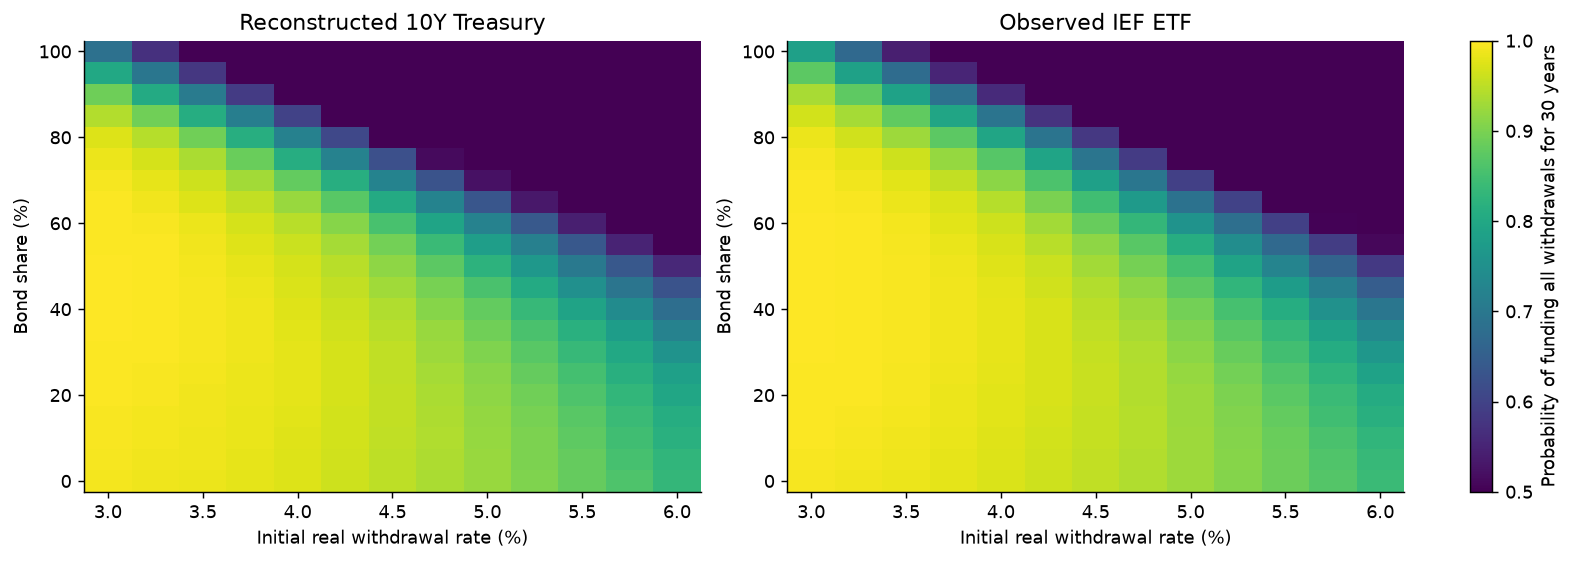

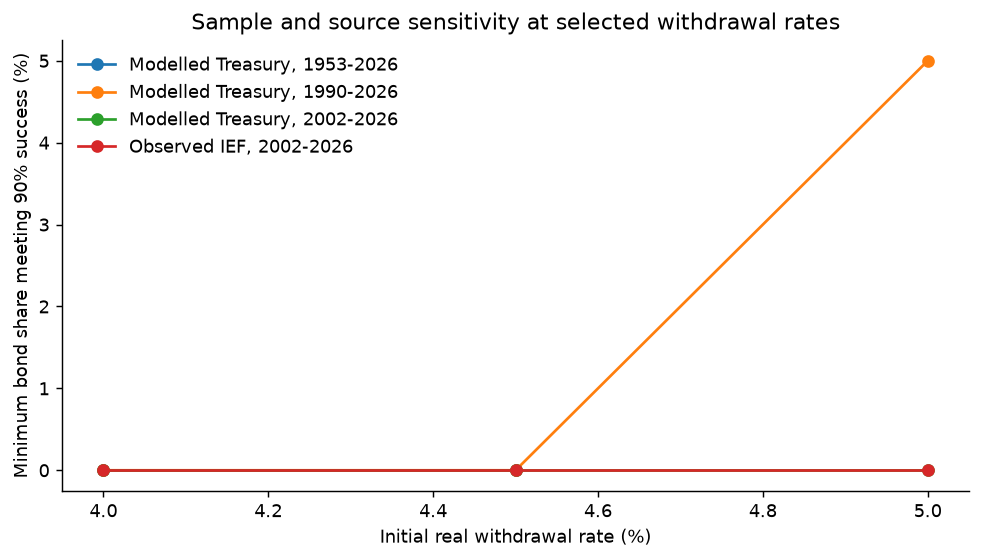

In [4]:
fig, axes = plt.subplots(1,2,figsize=(12,4.2),layout='constrained')
for ax, label, record in zip(axes, ['Reconstructed 10Y Treasury','Observed IEF ETF'],
                              [model['matched_model'], observed['matched_ief']]):
    r = results(record)
    image = ax.pcolormesh(np.array(r['r'])*100,np.array(r['b'])*100,
                         r['p_success']['30'], shading='nearest',vmin=.5,vmax=1,cmap='viridis')
    ax.set(xlabel='Initial real withdrawal rate (%)',ylabel='Bond share (%)',title=label)
fig.colorbar(image,ax=axes,label='Probability of funding all withdrawals for 30 years')
export('matched_success_heatmaps')

fig, ax = plt.subplots(figsize=(9,4.5))
for label in ['1953_full','1990_onward','matched_model','matched_ief']:
    frame = threshold_table[threshold_table['sample']==label]
    labels={'1953_full':'Modelled Treasury, 1953-2026','1990_onward':'Modelled Treasury, 1990-2026',
            'matched_model':'Modelled Treasury, 2002-2026','matched_ief':'Observed IEF, 2002-2026'}
    ax.plot(frame['withdrawal_rate']*100,frame['minimum_bond_share']*100,marker='o',label=labels[label])
ax.set(xlabel='Initial real withdrawal rate (%)',ylabel='Minimum bond share meeting 90% success (%)',
       title='Sample and source sensitivity at selected withdrawal rates')
ax.legend(frameon=False)
export('minimum_bond_share')


## Consumption utility versus withdrawal success

Certainty-equivalent consumption is the constant consumption level delivering the same expected discounted
CRRA utility. The original frontier is compared with the corrected common-horizon calculation below.
The independent-path evaluation then selects allocations using training paths only and reports their
paired differences on the test paths. The intervals measure simulation uncertainty conditional on the
calibrated model and selected policies.
[Utility implementation](https://github.com/tanishpatel0106/FI-Acc-Dec-Wedmont/blob/main/backend/lifecycle/engine/lifecycle/utility.py)


,calculation,ce_optimal_bond_share,success_optimal_bond_share,ce_optimal_success,success_optimal_success
0,Original 40Y utility / 30Y success,0.30,0.15,0.8780,0.887
1,Corrected 30Y utility / 30Y success,0.35,0.15,0.8715,0.887


,dataset,withdrawal_rate,ce_selected_bond_share,success_selected_bond_share,test_ce_gain,ci_lo,ci_hi,test_success_change
0,main,0.040,0.45,0.30,0.0389,0.0260,0.0518,-0.0056
1,main,0.045,0.40,0.10,0.1170,0.1011,0.1316,-0.0092
2,main,0.050,0.35,0.05,0.0873,0.0772,0.0976,-0.0209
3,main,0.055,0.30,0.00,0.0656,0.0579,0.0724,-0.0335
4,observed,0.040,0.45,0.35,0.0217,0.0100,0.0324,-0.0012
5,observed,0.045,0.40,0.25,0.0526,0.0378,0.0675,-0.0088
6,observed,0.050,0.35,0.05,0.1220,0.1068,0.1387,-0.0213
7,observed,0.055,0.30,0.00,0.0776,0.0672,0.0881,-0.0374


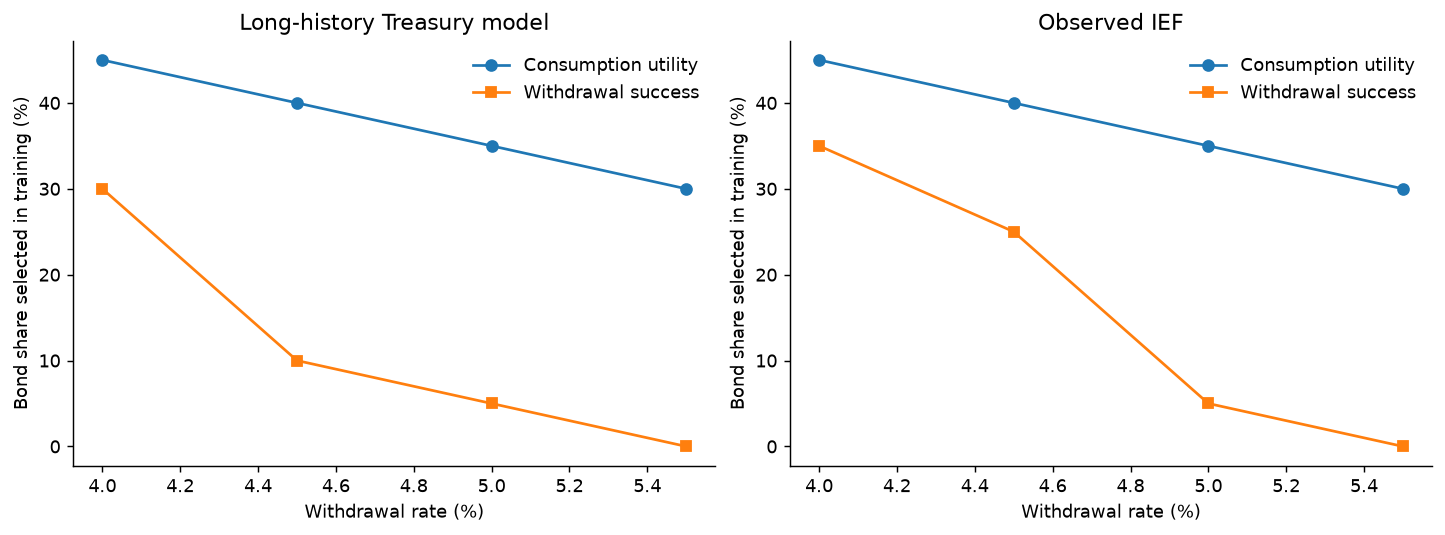

In [5]:
original = read('baseline_frontier.json')
corrected = results(main['frontier'])
comparison = []
for label, r in [('Original 40Y utility / 30Y success', original), ('Corrected 30Y utility / 30Y success', corrected)]:
    v = next(x for x in r['optima'] if np.isclose(x['r'],.05))
    comparison.append({'calculation':label, 'ce_optimal_bond_share':v['b_ce'],
                       'success_optimal_bond_share':v['b_survival'],
                       'ce_optimal_success':v['p_at_ce_opt'], 'success_optimal_success':v['p_at_surv_opt']})
display(pd.DataFrame(comparison))
allocation_rows=[]
for dataset in ['main','observed']:
    holdout = read(dataset+'_allocation_holdout.json')
    for r in holdout['results']:
        d=r['test_ce_delta_ce_vs_survival']
        allocation_rows.append({'dataset':dataset,'withdrawal_rate':r['withdrawal_rate'],
            'ce_selected_bond_share':r['trained_ce_bond_share'],
            'success_selected_bond_share':r['trained_survival_bond_share'],
            'test_ce_gain':d['delta'],'ci_lo':d['lo'],'ci_hi':d['hi'],
            'test_success_change':r['test_success_delta_ce_vs_survival']['diff']})
allocation_table=pd.DataFrame(allocation_rows)
allocation_table.to_csv(OUT/'allocation_holdout_summary.csv',index=False)
display(allocation_table.round(4))
fig, axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
for ax,dataset in zip(axes,['main','observed']):
    f=allocation_table[allocation_table['dataset']==dataset]
    ax.plot(f['withdrawal_rate']*100,f['ce_selected_bond_share']*100,'o-',label='Consumption utility')
    ax.plot(f['withdrawal_rate']*100,f['success_selected_bond_share']*100,'s-',label='Withdrawal success')
    title='Long-history Treasury model' if dataset=='main' else 'Observed IEF'
    ax.set(title=title,xlabel='Withdrawal rate (%)',ylabel='Bond share selected in training (%)')
    ax.legend(frameon=False)
export('trained_objective_comparison')


## Age and planned cash flows

The signed-flow surface defines q as planned annual net withdrawals divided by reference wealth. Negative q
represents saving. Its objective is CRRA utility of terminal real wealth plus funded draws. This resources
objective differs from the discounted consumption objective used above, so its numerical CE levels are
reported separately.

The surface contains no labour-income or human-capital channel. Holding its horizon fixed leaves no direct
age effect in the resources objective. The revised horizon mapping makes that structure visible. Survey
risk willingness and measured household loss capacity remain separate empirical inputs to the broader project.


,age,slope,lo,hi
0,25.0,-0.1747,-0.4102,0.4541
1,35.0,-0.1747,-0.4102,0.4541
2,45.0,-0.1747,-0.4102,0.4541
3,55.0,-0.1747,-0.4102,0.4541
4,65.0,-0.1747,-0.4102,0.4541
5,75.0,-0.1747,-0.4102,0.4541
6,85.0,0.4541,-0.2492,0.5619


,delta,lo,hi,n_boot,method
0,-0.003821,-0.006678,-0.000766,100,paired test-path percentile bootstrap across a...


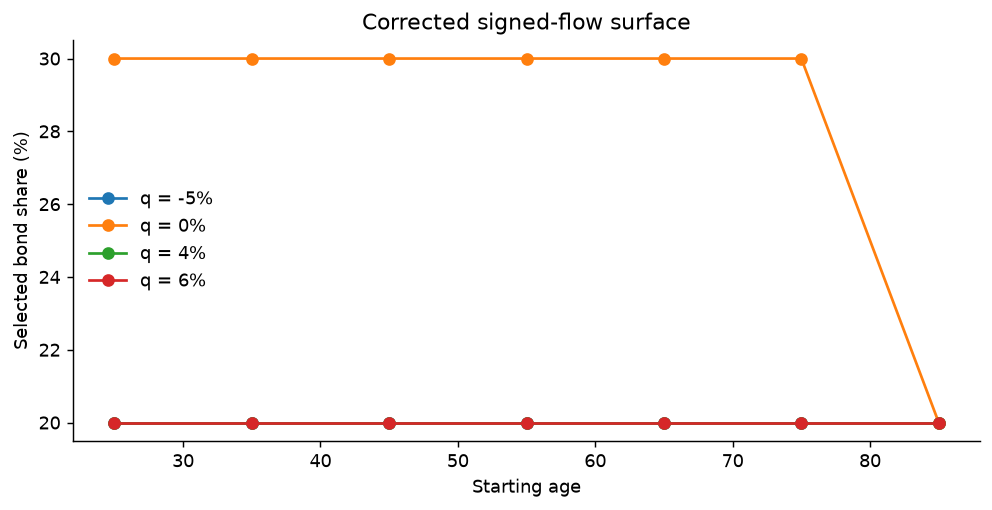

,dataset,max_horizon,split_year,mean_full_vs_age_delta,min_cohort_count,max_cohort_count
0,main,10,1990,0.0167,320,320
1,main,10,2000,-0.0086,200,200
2,main,10,2005,0.0154,140,140
3,main,10,2010,0.0317,80,80
4,main,10,2015,0.0545,20,20
5,main,20,1990,-0.0042,200,320
6,main,20,2000,0.0052,80,200
7,main,20,2005,0.0204,20,140
8,observed,10,2008,0.0000,104,104
9,observed,10,2012,0.0000,56,56


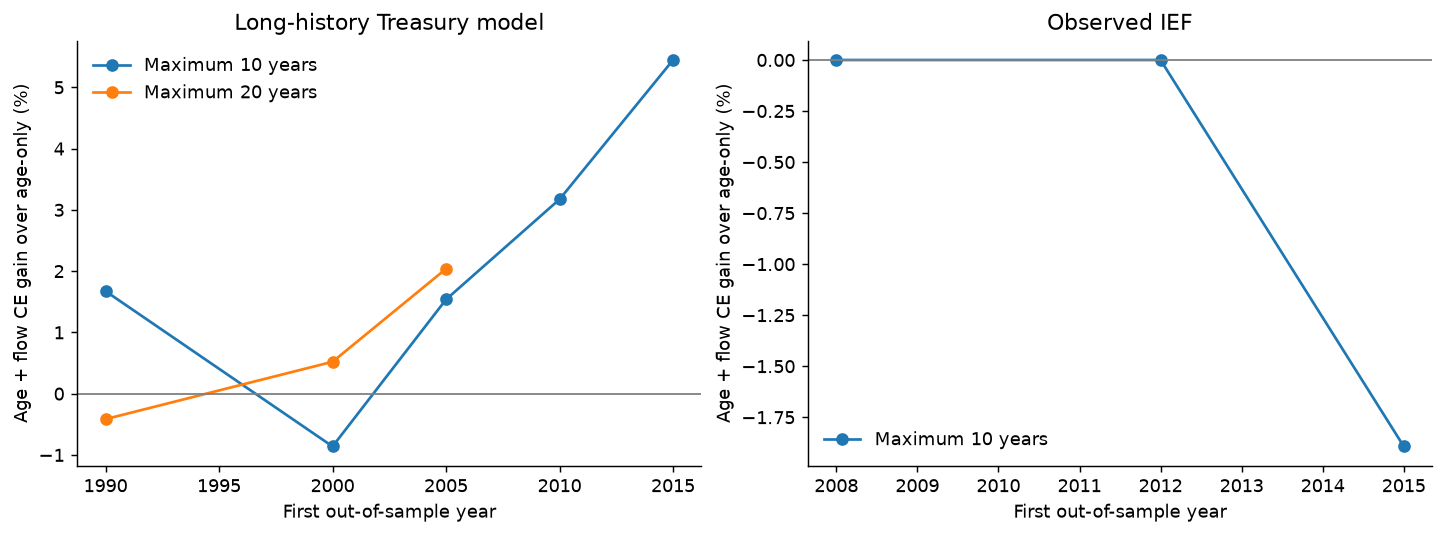

In [6]:
sf=results(main['signed_flow'])
display(pd.DataFrame(sf['slopes'])[['age','slope','lo','hi']].round(4))
display(pd.DataFrame([sf['policies']['oos_full_vs_age']]))
fig,ax=plt.subplots(figsize=(9,4))
for q in [-.05,0,.04,.06]:
    qi=int(np.argmin(np.abs(np.array(sf['q'])-q)))
    ax.plot(sf['ages'],np.array(sf['b_ce'])[:,qi]*100,marker='o',label=f'q = {q:.0%}')
ax.set(xlabel='Starting age',ylabel='Selected bond share (%)',title='Corrected signed-flow surface')
ax.legend(frameon=False)
export('age_and_flow_surface')

historical=pd.concat([pd.read_csv(OUT/(d+'_chronological_holdout.csv')) for d in ['main','observed']],ignore_index=True)
summary=historical.groupby(['dataset','max_horizon','split_year'],as_index=False).agg(
    mean_full_vs_age_delta=('full_vs_age_delta','mean'),
    min_cohort_count=('n_overlapping_cohorts','min'), max_cohort_count=('n_overlapping_cohorts','max'))
display(summary.round(4))
summary.to_csv(OUT/'chronological_summary.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
for ax,dataset in zip(axes,['main','observed']):
    f=summary[summary['dataset']==dataset]
    for horizon,g in f.groupby('max_horizon'):
        ax.plot(g['split_year'],g['mean_full_vs_age_delta']*100,'o-',label=f'Maximum {horizon} years')
    ax.axhline(0,color='grey',linewidth=1)
    title='Long-history Treasury model' if dataset=='main' else 'Observed IEF'
    ax.set(title=title,xlabel='First out-of-sample year',ylabel='Age + flow CE gain over age-only (%)')
    ax.legend(frameon=False)
export('chronological_holdout')


In [7]:
sim=sf['policies']['oos_full_vs_age']
window_rows=threshold_table[np.isclose(threshold_table['withdrawal_rate'],.05)]
display(Markdown(f"The corrected simulation estimates an age-plus-flow relative resources CE change of "
                 f"**{sim['delta']:.2%}**, with a paired 95% interval of "
                 f"**[{sim['lo']:.2%}, {sim['hi']:.2%}]**, against the age-only policy. "
                 "The chronological table reports whether this sign persists in later observed cohorts. "
                 "Each split retains its own result because the test windows and cohorts overlap."))
display(window_rows[['sample','minimum_bond_share','best_success','status']].round(4))


The corrected simulation estimates an age-plus-flow relative resources CE change of **-0.38%**, with a paired 95% interval of **[-0.67%, -0.08%]**, against the age-only policy. The chronological table reports whether this sign persists in later observed cohorts. Each split retains its own result because the test windows and cohorts overlap.

,sample,minimum_bond_share,best_success,status
2,1953_full,NaN,0.8700,no_feasible_allocation
6,1990_onward,0.05,0.9088,identified
10,1990_onward_cost5bps,0.05,0.9088,identified
14,matched_model,0.00,0.9234,no_bonds_needed
18,matched_model_2002_2013,NaN,0.8896,no_feasible_allocation
22,matched_model_2014_onward,0.00,0.9812,no_bonds_needed
26,matched_ief,0.00,0.9270,no_bonds_needed
30,matched_ief_cost5bps,0.00,0.9266,no_bonds_needed
34,ief_2002_2013,0.35,0.9270,identified
38,ief_2014_onward,0.00,0.9796,no_bonds_needed


## Permanent Portfolio and reproducibility

Observed GLD returns allow the previously unavailable classic Permanent Portfolio study to run. Its
Treasury sleeves retain the original return reconstruction, and its comparison uses the joint available
history. The table reports the paired simulation interval against the 60/40 benchmark.


In [8]:
pp=results(observed['permanent_with_observed_gold'])
pp_rows=[]
for r in pp['scorecard']:
    d=r.get('delta_ce_vs_benchmark',{})
    pp_rows.append({'policy':r['policy'],'annual_ce':r['ce']['ce'],
                    'success_30y':r['success']['30']['p'],
                    'delta_ce_vs_6040':d.get('delta',0), 'ci_lo':d.get('lo'), 'ci_hi':d.get('hi'),
                    'unmet_spending_cvar95':r['severity']['cvar95_unconditional']})
display(pd.DataFrame(pp_rows).round(4))
pp_table=pd.DataFrame(pp_rows)
pp_table.to_csv(OUT/'permanent_portfolio_summary.csv',index=False)
display(pd.DataFrame([read('verification.json')]).T.rename(columns={0:'verification'}))


,policy,annual_ce,success_30y,delta_ce_vs_6040,ci_lo,ci_hi,unmet_spending_cvar95
0,sixty_forty,27398.9170,0.9690,0.0000,NaN,NaN,96972.7837
1,pp_classic,28417.9911,0.9685,0.0372,-0.0486,0.1181,90812.8398
2,pp_monthly,27101.1996,0.9610,-0.0109,-0.0965,0.0606,113164.3876
3,pp_annual,28023.7980,0.9630,0.0228,-0.0649,0.0931,98445.4744
4,pp_15_35_monthly,28335.9431,0.9690,0.0342,-0.0541,0.1098,92769.3056
5,pp_5pp_band,27916.7940,0.9665,0.0189,-0.0671,0.0901,100118.4025
6,pp_intermediate,29197.3402,0.9700,0.0656,-0.0235,0.1433,83584.8915
7,pp_cash_buffer,26877.5277,0.9640,-0.0190,-0.1051,0.0609,111012.6324
8,pp_no_gold,17748.2430,0.7715,-0.3522,-0.4090,-0.2978,266923.2806
9,pp_no_long_duration,29577.4717,0.9610,0.0795,-0.0079,0.1517,84915.7007


,verification
backend_tests,111 passed
frontend_unit_tests,230 passed
typecheck,passed
production_build,"passed, Next.js 16.4.6"
lint,"0 errors, 1 existing React Hook Form warning"
browser_tests,26 passed
exact_reproduction,{'reproduce_frontier.log': 'reproduced 1539625...
historical_replay_checks,"{'return_information_precedes_decision': True,..."
dependency_audit,"6 advisories remain (1 high, 4 moderate, 1 low..."
WRDS,"Completed Duo, explicit Terms of Use acceptanc..."


## Reproduction and outstanding dependencies

From the repository root, install the locked backend environment and web dependencies, rebuild the public
snapshot panel, and run the studies. The optional observed data are kept in `data/validation_etfs`.

```powershell
python -m uv sync --project backend --extra dev --extra wrds --extra workers --frozen
backend/.venv/Scripts/python.exe -m lifecycle.cli ingest --offline
backend/.venv/Scripts/python.exe research/validate_followup.py --stage all
$env:LIFECYCLE_DATA_DIR='data/validation_etfs'
backend/.venv/Scripts/python.exe -m lifecycle.data.ingest_public_etfs --snapshot research/followup_2026_11_19/observed_etf_monthly_returns.csv
backend/.venv/Scripts/python.exe research/validate_followup.py --stage all --dataset observed
Remove-Item Env:LIFECYCLE_DATA_DIR
backend/.venv/Scripts/python.exe research/validate_allocation_holdout.py
backend/.venv/Scripts/python.exe research/validate_allocation_holdout.py --observed
```

For a clean rerun, copy `data/raw` and `data/processed` into the corresponding folders under
`data/validation_etfs` before observed ingestion. An executed notebook accompanies the persisted derived
results. Raw daily vendor responses remain local. The frozen monthly return snapshot is included.
`validation_manifest.json` records SHA-256 hashes of the report inputs.

WRDS authentication and extraction have now been completed. The separate
[WRDS validation extension](../wrds_validation_2026_11_19/wrds_validation.html) reports 12 matched-window
frontiers, independent allocation tests, eight chronological folds per panel, and the full multi-asset
universe. It uses CRSP Treasury, equity, cash and inflation inputs and licensed ETF data. Raw licensed
observations are excluded from the report and package. These results supersede the earlier pending-WRDS
status, while the public-data results above remain their documented baseline.
The extension now also corrects the WRDS signed-flow universe, evaluates 26 sensitivity configurations,
100 training-history refits and nonoverlapping complete holding periods. Its corrected conditional-rule
interval includes zero; the initial six-asset WRDS estimate is retained only as a superseded audit record.

Employer installation awaits the employer's
reply and GitHub username. The repository access and local execution steps remain pending that response.
The reviewed email, Drive search and project files yielded the meeting invitation and follow-up email.
A recording link and transcript have yet to be located.

### References and provenance

- Tanish's employer follow-up, November 10, 2026, and the project application guide.
- [Project source and original result summary](https://github.com/tanishpatel0106/FI-Acc-Dec-Wedmont/blob/4b0c23ec63f760feb8bcfbaecddd5746921f21d4/docs/APP_GUIDE.md)
- [Project pre-analysis plan](https://github.com/tanishpatel0106/FI-Acc-Dec-Wedmont/blob/main/research/preregistration/analysis_plan.md)
- [Kenneth French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html)
- [FRED CPIAUCNS](https://fred.stlouisfed.org/series/CPIAUCNS)
- [Federal Reserve Treasury yield-curve research](https://www.federalreserve.gov/econres/feds/the-us-treasury-yield-curve-1961-to-the-present.htm)
- [IEF fund and maturity definition](https://www.ishares.com/us/products/239456/ishares-710-year-treasury-bond-etf)
- [Yahoo Finance IEF historical observations](https://finance.yahoo.com/quote/IEF/history/)
- [Yahoo Finance GLD historical observations](https://finance.yahoo.com/quote/GLD/history/)

The repository bibliography supplies the broader lifecycle and bootstrap literature. This follow-up
reproduces and audits the project's implemented model. The independent historical tests evaluate its fitted
allocation rules on later returns.
